# Loan Default Prediction
**A Project Notebook** — Default of Credit Card Clients (UCI)

Submitted in partial fulfilment for the award of the degree of **MBA (Data Science and Artificial Intelligence)**, Chandigarh University.

---
## Chapter 1: Introduction

### 1.1 Overview
Credit-card lenders earn interest and fees from customers who repay on time. When a customer stops paying, the lender loses that income and must spend money on reminders and collection. Knowing in advance which customers are likely to miss their next payment lets a risk team act early, for example by sending a reminder, reviewing a credit limit, or offering a repayment plan.

This project uses the *Default of Credit Card Clients* dataset from the UCI Machine Learning Repository to estimate whether a customer will default in the following month. Three classifiers are compared: **Logistic Regression**, a **Decision Tree**, and a **Random Forest**.

### 1.2 Problem Statement
Given a customer's credit limit, profile, repayment status, bill amounts, and past payments, predict whether the customer will default on a payment next month. This is binary classification, made harder by the fact that only about one customer in five defaults.

### 1.3 Objectives
- Study the dataset and find which customer groups default the most.
- Build Logistic Regression, Decision Tree, and Random Forest classifiers.
- Compare the three models on the same test data.
- Judge the models using Accuracy, Precision, Recall, F1-score, and ROC-AUC rather than accuracy alone.
- Explain which features drive default and discuss the limits of such a model.

### 1.4 Scope
This is a learning prototype, not a production lending system. The data describes credit-card clients of a bank in Taiwan, recorded in 2005. Findings must not be treated as evidence about current Indian borrowers or personal loans without local data and validation.

### 1.5 Why Compare Three Models?
- **Logistic Regression**: quick, explainable, each feature has a clear weight.
- **Decision Tree**: short if/then rules that are easy to read.
- **Random Forest**: combines many trees and captures complex patterns, but is harder to explain.

In [6]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 100

---
## Chapter 2: Dataset and Analysis

### 2.1 The Dataset
The dataset (Yeh, 2009) describes 30,000 credit-card customers of a bank in Taiwan. Each customer has 23 input details:

| Group | Features |
|---|---|
| Credit | `LIMIT_BAL`: credit granted, in New Taiwan dollars |
| Profile | Sex, education, marital status, age |
| Repayment status | `PAY_0`, `PAY_2`–`PAY_6`: status in each of the past six months (−1 = paid on time; positive = months of delay) |
| Bill statements | `BILL_AMT1`–`BILL_AMT6` |
| Previous payments | `PAY_AMT1`–`PAY_AMT6` |
| Target | Default payment next month (Yes / No) |

**Loading the data.** The cell below tries, in order: (1) a local copy of the file (download from the UCI link in the References and place it next to this notebook), (2) the `ucimlrepo` package, (3) OpenML.

In [7]:
def load_data():
    # 1) Local file (UCI original .xls, or a .csv version)
    for f in ["default of credit card clients.xls", "default_of_credit_card_clients.xls",
              "default of credit card clients.csv", "UCI_Credit_Card.csv"]:
        if os.path.exists(f):
            if f.endswith(".xls"):
                return pd.read_excel(f, header=1)          # needs xlrd
            return pd.read_csv(f)
    # 2) ucimlrepo
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=350)
        df = pd.concat([d.data.features, d.data.targets], axis=1)
        return df
    except Exception as e:
        print("ucimlrepo failed:", e)
    # 3) OpenML
    from sklearn.datasets import fetch_openml
    return fetch_openml(data_id=42477, as_frame=True).frame

raw = load_data()

# Standardise column names to uppercase to catch both 'X1' and 'x1'
raw.columns = [c.upper() for c in raw.columns]

if "X1" in raw.columns:
    names = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", "PAY_0", "PAY_2", "PAY_3",
              "PAY_4", "PAY_5", "PAY_6"] + [f"BILL_AMT{i}" for i in range(1, 7)]
             + [f"PAY_AMT{i}" for i in range(1, 7)])
    raw = raw.rename(columns={f"X{i+1}": n for i, n in enumerate(names)})
    raw = raw.rename(columns={"Y": "default"})

raw = raw.rename(columns={"PAY_1": "PAY_0",
                          "DEFAULT PAYMENT NEXT MONTH": "default",
                          "DEFAULT.PAYMENT.NEXT.MONTH": "default",
                          "DEFAULT": "default"})
raw = raw.drop(columns=[c for c in ["ID", "id"] if c in raw.columns], errors="ignore")
raw = raw.apply(pd.to_numeric)
print(raw.shape)
raw.head()

ucimlrepo failed: No module named 'ucimlrepo'
(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 2.2 How Many Customers Default?

Total: 30,000 | Default: 6,636 (22.12%) | No default: 23,364
A model that always predicts 'no default' would be right 77.9% of the time.


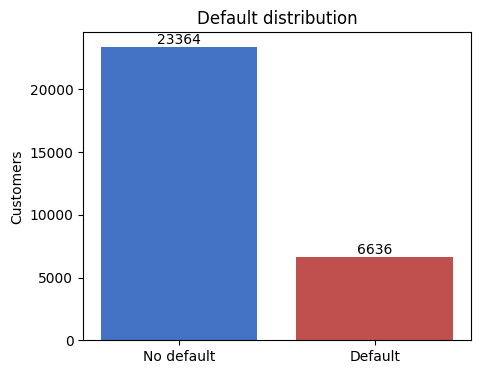

In [8]:
counts = raw["default"].value_counts().sort_index()
rate = raw["default"].mean()
print(f"Total: {len(raw):,} | Default: {counts[1]:,} ({rate:.2%}) | No default: {counts[0]:,}")
print(f"A model that always predicts 'no default' would be right {1-rate:.1%} of the time.")

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["No default", "Default"], counts.values, color=["#4472C4", "#C0504D"])
ax.bar_label(bars)
ax.set_ylabel("Customers"); ax.set_title("Default distribution")
plt.show()

*Figure 2.1 — Default distribution.* Because the two groups are so uneven, accuracy alone is not enough; precision, recall and F1-score are examined as well.

### 2.3 Who Is Most Likely to Default?

In [9]:
def rate_of(mask):
    return raw.loc[mask, "default"].mean() * 100

summary = pd.DataFrame({
    "Customer group": [
        "Latest status: revolving / paid minimum (PAY_0 = 0)",
        "Latest status: one month late (PAY_0 = 1)",
        "Latest status: two months late (PAY_0 = 2)",
        "Latest status: three months late (PAY_0 = 3)",
        "Credit limit up to NT$50,000",
        "Credit limit above NT$200,000"],
    "Default rate (%)": [
        rate_of(raw.PAY_0 == 0), rate_of(raw.PAY_0 == 1), rate_of(raw.PAY_0 == 2),
        rate_of(raw.PAY_0 == 3), rate_of(raw.LIMIT_BAL <= 50000),
        rate_of(raw.LIMIT_BAL > 200000)]}).round(1)
summary

,Customer group,Default rate (%)
0,Latest status: revolving / paid minimum (PAY_0...,12.8
1,Latest status: one month late (PAY_0 = 1),33.9
2,Latest status: two months late (PAY_0 = 2),69.1
3,Latest status: three months late (PAY_0 = 3),75.8
4,"Credit limit up to NT$50,000",31.8
5,"Credit limit above NT$200,000",14.7


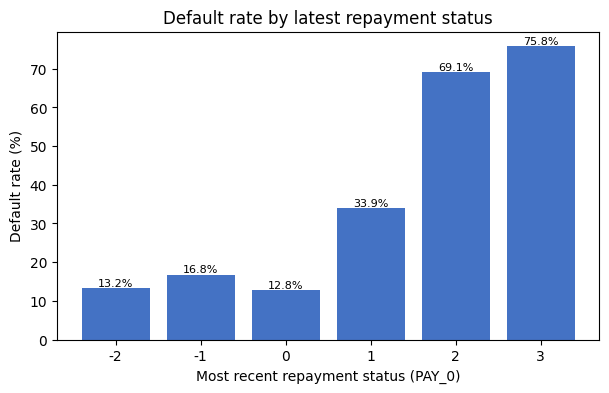

In [10]:
pay0 = raw[raw.PAY_0.between(-2, 3)].groupby("PAY_0")["default"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(pay0.index.astype(str), pay0.values, color="#4472C4")
ax.bar_label(bars, fmt="%.1f%%", fontsize=8)
ax.set_xlabel("Most recent repayment status (PAY_0)")
ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by latest repayment status")
plt.show()

*Figure 2.2 — Default rate by latest repayment status.*

In [11]:
age_bands = pd.cut(raw.AGE, [20, 30, 40, 50, 60, 100], labels=["21-30", "31-40", "41-50", "51-60", "61+"])
print("Default rate by age band (%):")
print((raw.groupby(age_bands)["default"].mean() * 100).round(1).to_string())
print()
print("Default rate by sex (1 = male, 2 = female) (%):")
print((raw.groupby("SEX")["default"].mean() * 100).round(1).to_string())

Default rate by age band (%):
AGE
21-30    22.4
31-40    20.4
41-50    23.3
51-60    25.2
61+      26.8

Default rate by sex (1 = male, 2 = female) (%):
SEX
1    24.2
2    20.8


Age shows only a mild pattern, and male customers default slightly more often than female customers. These are descriptive patterns and **do not establish cause**. They also show why demographic variables need careful fairness checks in any real lending use.

### 2.4 Data Quality

In [12]:
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows (ID ignored):", int(raw.duplicated().sum()), "(kept: different customers can have identical details)")
print("Undocumented EDUCATION codes (0, 5, 6):", int(raw.EDUCATION.isin([0, 5, 6]).sum()))
print("Undocumented MARRIAGE code (0):", int((raw.MARRIAGE == 0).sum()))
print(f"Mean credit limit: NT${raw.LIMIT_BAL.mean():,.0f} | median: NT${raw.LIMIT_BAL.median():,.0f}")
print(f"Mean age: {raw.AGE.mean():.1f} years")

Missing values: 0
Duplicate rows (ID ignored): 35 (kept: different customers can have identical details)
Undocumented EDUCATION codes (0, 5, 6): 345
Undocumented MARRIAGE code (0): 54
Mean credit limit: NT$167,484 | median: NT$140,000
Mean age: 35.5 years


---
## Chapter 3: Methodology

### 3.1 Data Preparation
1. Remove the customer ID column.
2. Group undocumented education codes (0, 5, 6) into "Others" (4) and marital code 0 into "Other" (3).
3. Fill any missing numeric values with the median (none found; kept as a safeguard).
4. Scale the numeric columns (needed for Logistic Regression).
5. One-hot encode sex, education and marital status → **26 input features**.
6. Split 80:20 into training (24,000) and test (6,000) sets, stratified on the target.

All steps sit inside one Scikit-learn `Pipeline`, so test data never influences the training stage.

In [13]:
df = raw.copy()
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

X = df.drop(columns="default")
y = df["default"].astype(int)

cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Default share  train: %.2f%%  test: %.2f%%" % (y_train.mean()*100, y_test.mean()*100))

Train: (24000, 23) | Test: (6000, 23)
Default share  train: 22.12%  test: 22.12%


### 3.2 Models Used
Logistic Regression multiplies each input by a learned weight, adds a bias, and passes the total through the sigmoid function; a customer is predicted to default when the probability is ≥ 0.5.

$$P(\text{default}) = \frac{1}{1 + e^{-(b_0 + b_1x_1 + b_2x_2 + \dots + b_{26}x_{26})}}$$

| Model | Setting | Purpose |
|---|---|---|
| Logistic Regression | up to 1,000 iterations, default regularisation | Simple, explainable baseline |
| Decision Tree | maximum depth 4 | Easy-to-follow if/then rules |
| Random Forest | 200 trees, maximum depth 8 | Captures complex, non-linear patterns |

### 3.3 Evaluation Measures
**Accuracy** – share of correct predictions. **Precision** – how many predicted defaulters really defaulted. **Recall** – how many real defaulters were found. **F1-score** – balance of precision and recall. **ROC-AUC** – how well a model ranks defaulters above non-defaulters across all thresholds.

Recall matters because every missed defaulter is a possible loss; precision matters because wrongly flagged customers face unnecessary checks.

### 3.4 Prediction Threshold
A threshold of **0.50** is used for the main comparison. This is only a classroom choice; a real lender should set it using validation data, business costs, regulation and fairness testing (see 4.4).

### 3.5 Reproducibility
A fixed random state of 42 is used for the split and the models. Small differences may appear if the dataset or library versions change.

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE),
}

pipes = {name: Pipeline([("prep", preprocess), ("model", m)]).fit(X_train, y_train)
         for name, m in models.items()}

n_features = pipes["Logistic Regression"].named_steps["prep"].transform(X_train).shape[1]
print("Input features after encoding:", n_features)

Input features after encoding: 26


---
## Chapter 4: Results

### 4.1 Model Comparison
All three models are tested on the same 6,000 unseen customers.

In [15]:
proba = {n: p.predict_proba(X_test)[:, 1] for n, p in pipes.items()}
pred = {n: (proba[n] >= 0.5).astype(int) for n in pipes}

rows = []
for n in pipes:
    rows.append({"Model": n,
                 "Accuracy": accuracy_score(y_test, pred[n]),
                 "Precision": precision_score(y_test, pred[n]),
                 "Recall": recall_score(y_test, pred[n]),
                 "F1-score": f1_score(y_test, pred[n]),
                 "ROC-AUC": roc_auc_score(y_test, proba[n])})
results = pd.DataFrame(rows).set_index("Model")

print(f"Test set: {len(y_test):,} customers, {int(y_test.sum()):,} actually defaulted")
print(f"'Always no default' accuracy on this test set: {1 - y_test.mean():.1%}")
results.style.format({"Accuracy": "{:.2%}", "Precision": "{:.2%}", "Recall": "{:.2%}",
                      "F1-score": "{:.2%}", "ROC-AUC": "{:.4f}"})

Test set: 6,000 customers, 1,327 actually defaulted
'Always no default' accuracy on this test set: 77.9%


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,80.88%,69.23%,24.42%,36.10%,0.7101
Decision Tree,81.80%,65.94%,36.62%,47.09%,0.7340
Random Forest,81.68%,66.52%,34.59%,45.51%,0.7736


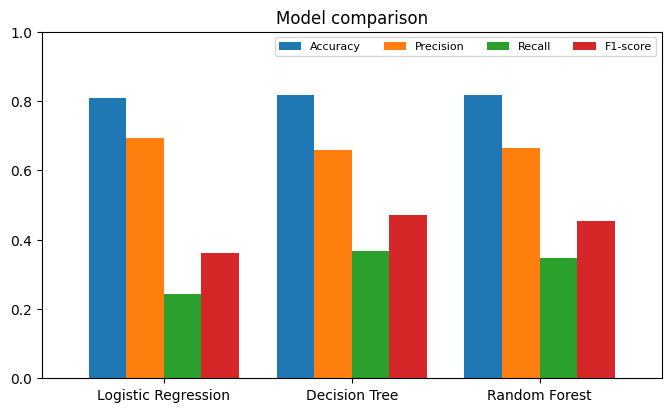

In [16]:
ax = results[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(8, 4.5), width=0.8,
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"])
ax.set_ylim(0, 1); ax.set_title("Model comparison"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.legend(ncol=4, fontsize=8)
plt.show()

*Figure 4.1 — Model comparison.* Random Forest gives the best ROC-AUC (best at ranking by risk); the Decision Tree is slightly ahead on accuracy, recall and F1; Logistic Regression has the highest precision but the lowest recall. All accuracies are only a little above the 'always no default' baseline.

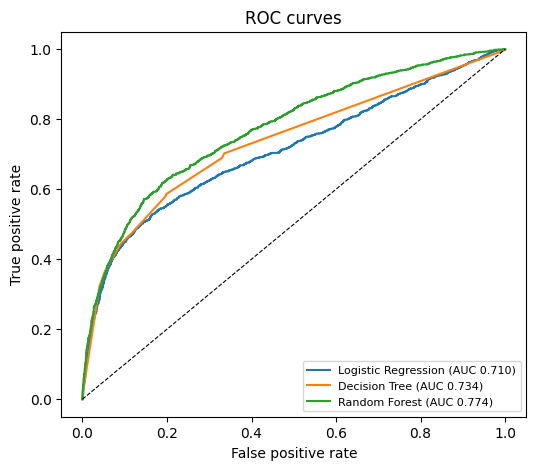

In [17]:
colors = {"Logistic Regression": "tab:blue", "Decision Tree": "tab:orange", "Random Forest": "tab:green"}
fig, ax = plt.subplots(figsize=(6, 5))
for n in pipes:
    fpr, tpr, _ = roc_curve(y_test, proba[n])
    ax.plot(fpr, tpr, color=colors[n], label=f"{n} (AUC {roc_auc_score(y_test, proba[n]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves"); ax.legend(loc="lower right", fontsize=8)
plt.show()

*Figure 4.2 — ROC curves of the three models.*

### 4.2 Confusion Matrix of Random Forest

,Predicted: No,Predicted: Yes
Actual: No,4442,231
Actual: Yes,868,459


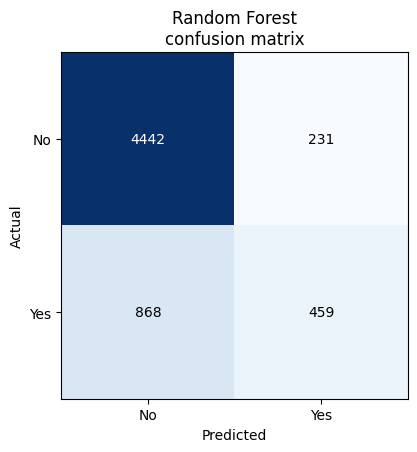

Of 1,327 real defaulters the model found 459 and missed 868; it wrongly flagged 231 customers.


In [18]:
cm = confusion_matrix(y_test, pred["Random Forest"])
display(pd.DataFrame(cm, index=["Actual: No", "Actual: Yes"], columns=["Predicted: No", "Predicted: Yes"]))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["No", "Yes"]); ax.set_yticks([0, 1], ["No", "Yes"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Random Forest\nconfusion matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Of {tp+fn:,} real defaulters the model found {tp} and missed {fn}; it wrongly flagged {fp} customers.")

*Figure 4.3 — Confusion matrix.* Missed defaulters are the costlier error for a lender, so recall is the main area for improvement.

### 4.3 What the Models Learned

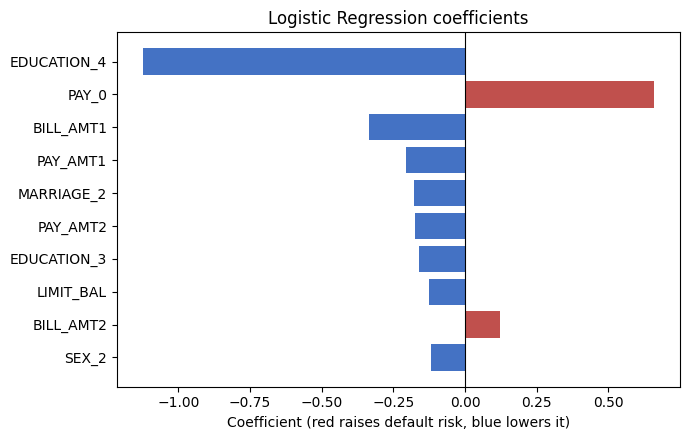

In [19]:
feat_names = pipes["Logistic Regression"].named_steps["prep"].get_feature_names_out()
feat_names = [n.split("__", 1)[1] for n in feat_names]
# match report-style names, e.g. SEX_2, EDUCATION_3, MARRIAGE_2
lr_coef = pd.Series(pipes["Logistic Regression"].named_steps["model"].coef_[0], index=feat_names)
top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).head(10).index)[::-1]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, color=["#C0504D" if v > 0 else "#4472C4" for v in top.values])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Coefficient (red raises default risk, blue lowers it)")
ax.set_title("Logistic Regression coefficients")
plt.tight_layout(); plt.show()

*Figure 4.4 — Logistic Regression coefficients (top 10 by size).*

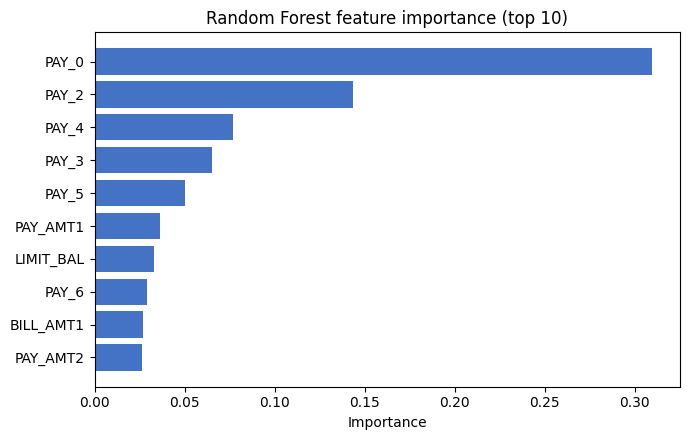

In [20]:
rf_imp = pd.Series(pipes["Random Forest"].named_steps["model"].feature_importances_, index=feat_names)
top_rf = rf_imp.sort_values(ascending=False).head(10)[::-1]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_rf.index, top_rf.values, color="#4472C4")
ax.set_xlabel("Importance"); ax.set_title("Random Forest feature importance (top 10)")
plt.tight_layout(); plt.show()

*Figure 4.5 — Random Forest feature importance (top 10).*

- The most recent repayment status (`PAY_0`) is the strongest driver in both models; later months (`PAY_2`–`PAY_5`) follow in the Random Forest.
- Larger recent payments and larger credit limits are linked with lower predicted risk in Logistic Regression.
- Bill amounts are strongly related to each other, and the "Others" education group is small, so those individual coefficients should be read with caution.
- Importance and coefficients describe patterns in the data; they do not prove cause and effect.

### 4.4 Effect of a Lower Threshold
Because recall was low at the default threshold, Logistic Regression is re-scored at lower thresholds on the same test set.

In [21]:
rows = []
for t in [0.50, 0.40, 0.30, 0.25]:
    p = (proba["Logistic Regression"] >= t).astype(int)
    rows.append({"Threshold": f"{t:.2f}" + (" (default)" if t == 0.5 else ""),
                 "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p),
                 "F1-score": f1_score(y_test, p), "Accuracy": accuracy_score(y_test, p)})
thr = pd.DataFrame(rows).set_index("Threshold")
thr.style.format("{:.2%}")

,Precision,Recall,F1-score,Accuracy
Threshold,,,,
0.50 (default),69.23%,24.42%,36.10%,80.88%
0.40,63.14%,37.83%,47.31%,81.37%
0.30,55.24%,45.67%,50.00%,79.80%
0.25,44.20%,55.09%,49.04%,74.68%


Lowering the threshold catches more defaulters (higher recall) but flags more reliable customers by mistake (lower precision). These thresholds are compared on the test set **only to illustrate the trade-off**; a real lender should choose a threshold on separate validation data and weigh the cost of each error type.

### 4.5 Discussion
- Random Forest ranked customers best, but no single model won on every measure, so the choice depends on the business goal.
- Logistic Regression is the easiest to explain, and lowering its threshold narrowed the recall gap.
- All three models found only about a quarter to a third of the defaulters at the default threshold, so none is ready for real lending use without improvement.

---
## Chapter 5: Conclusion

### 5.1 Conclusion
This project predicted next-month credit-card default using Logistic Regression, a Decision Tree, and a Random Forest. Random Forest achieved the highest ROC-AUC (about 0.77); the Decision Tree reached the highest accuracy and recall; Logistic Regression reached the highest precision. The recent repayment status was the clearest warning sign of default. The results also show that imbalanced data must be judged with more than accuracy.

### 5.2 Limitations
- The dataset is historical (2005), from Taiwan, and concerns credit-card clients rather than personal loans.
- Only about 22% of customers default, which makes defaulters hard to detect.
- Basic settings and a single train-test split; no cross-validation or tuning.
- Demographic variables (sex, education, marital status) may lead to unfair outcomes; no fairness testing was done.
- Predicted probabilities are not guarantees, and feature importance does not prove cause and effect.

### 5.3 Recommendations and Future Work
- Use the model as a decision-support signal for trained analysts, not as an automatic decision-maker.
- Send early reminders or offer support to customers already one month late.
- Raise recall using class weights or a lower threshold chosen on validation data and business costs.
- Use cross-validation and hyperparameter tuning, and test stronger models such as Gradient Boosting.
- Check probability calibration and measure performance across customer groups for fairness.
- Validate on recent, authorised data from the relevant lending market before drawing conclusions about another country or product.

---
## References
1. Yeh, I. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H
2. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
3. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.
4. Scikit-learn Developers. LogisticRegression, DecisionTreeClassifier, RandomForestClassifier documentation. https://scikit-learn.org